# Session 6  - CNN - Torch

CNN : U-Net , Downsampling , Maxsampling , Conv2dTranspose, AutoEncoder , Object detection vs classifier, R-CNN_

Torch : building from scratch

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset

## Class Material

**Kronecker Product (Kron) Upsampling**, **Pooling vs. Upsampling**, **Transposed Convolutions**, and how they power **Autoencoders**.

---

## 1. Downsampling vs. Upsampling (No Learning)

In deep learning, changing spatial dimensions (width $\times$ height) without adding trainable weights relies on fixed mathematical operations:

* **Downsampling without Learning (Max / Average Pooling):**
* **How it works:** Slides a window over the input feature map and takes either the maximum value or average value within that window.
* **Purpose:** Reduces spatial dimensions (e.g., from $32 \times 32$ to $16 \times 16$), increases the receptive field, and provides translation invariance.
* **Parameters:** $0$ trainable weights.


* **Upsampling without Learning (Kronecker Product / Nearest Neighbor / Bilinear):**
* **How it works:** Increases the spatial dimensions by repeating or interpolating values without fitting parameters.
* **Kronecker Product ($\otimes$):** Given a feature matrix $A$ and a matrix of ones $J_{k \times k}$, the Kronecker product replaces every single scalar element $a_{ij}$ in $A$ with a block $a_{ij} \cdot J_{k \times k}$.
* **Example:** Upsampling by a factor of $2$ ($k=2$):

$$A = \begin{bmatrix} 1 & 2 \\ 3 & 4 \end{bmatrix}, \quad J_{2 \times 2} = \begin{bmatrix} 1 & 1 \\ 1 & 1 \end{bmatrix}$$


$$A \otimes J_{2 \times 2} = \begin{bmatrix} 1 \cdot \begin{bmatrix} 1 & 1 \\ 1 & 1 \end{bmatrix} & 2 \cdot \begin{bmatrix} 1 & 1 \\ 1 & 1 \end{bmatrix} \\ 3 \cdot \begin{bmatrix} 1 & 1 \\ 1 & 1 \end{bmatrix} & 4 \cdot \begin{bmatrix} 1 & 1 \\ 1 & 1 \end{bmatrix} \end{bmatrix} = \begin{bmatrix} 1 & 1 & 2 & 2 \\ 1 & 1 & 2 & 2 \\ 3 & 3 & 4 & 4 \\ 3 & 3 & 4 & 4 \end{bmatrix}$$




* **Purpose:** Expands spatial resolution before or after convolutions without adding model parameters.
* **Parameters:** $0$ trainable weights.



---

## 2. Learnable Upsampling: `Conv2DTranspose`

While standard upsampling (like Kron or nearest neighbor) duplicates pixels naively, **Transposed Convolution** (often called `Conv2DTranspose` or Deconvolution) allows the neural network to **learn** how to best upscale spatial dimensions.

| Metric / Property | Standard Convolution (`Conv2D`) | Transposed Convolution (`Conv2DTranspose`) |
| --- | --- | --- |
| **Primary Effect** | Downsamples or retains resolution | Upsamples resolution |
| **Input $\to$ Output Mapping** | Maps multiple input pixels into $1$ output pixel | Maps $1$ input pixel into multiple output values |
| **Learnable Parameters** | Yes (Kernel weights) | Yes (Kernel weights) |
| **Common Application** | Feature extraction, Encoders | Reconstruction, Decoders, Segmentation |

### How `Conv2DTranspose` Works:

1. For every single pixel in the input feature map, multiply it by a learnable filter kernel.
2. Place the resulting scaled kernel block on the output grid.
3. Where output blocks overlap (due to stride), sum the values together.
4. Over gradient descent, the network learns the best kernel values to reconstruct fine spatial details.

---

## 3. Autoencoders: Putting It Together

An **Autoencoder** is an unsupervised architecture trained to reconstruct its input ($X \to \hat{X}$). It consists of two main parts:

$$\text{Input } X \xrightarrow[\text{Downsampling}]{\text{Encoder}} \text{Latent Vector } Z \xrightarrow[\text{Upsampling}]{\text{Decoder}} \text{Output } \hat{X}$$

```
Input Image (28x28)
       │
       ▼
 ┌───────────┐
 │  Encoder  │ ──> Uses Conv2D + MaxPool2D to compress spatial details
 └───────────┘
       │
       ▼
Latent Space (Z)  ──> Bottleneck representation (e.g., 1x16 vector)
       │
       ▼
 ┌───────────┐
 │  Decoder  │ ──> Uses Conv2DTranspose (or Kron/Upsample + Conv2D) to reconstruct
 └───────────┘
       │
       ▼
Reconstructed Image (28x28)

```

### Key Autoencoder Concepts:

* **The Bottleneck ($Z$):** Forces the network to learn a compressed, dense representation of data rather than simply memorizing the input.
* **Loss Function:** Typically **Mean Squared Error (MSE)** or **Binary Cross-Entropy (BCE)** comparing $X$ and $\hat{X}$:

$$\mathcal{L}(X, \hat{X}) = \frac{1}{N} \sum (X - \hat{X})^2$$


* **Applications:**
* **Denoising:** Removing noise from corrupted inputs.
* **Dimensionality Reduction:** Non-linear alternative to PCA.
* **Semantic Segmentation:** Encoders capture "what" is in the image, decoders reconstruct "where" it is spatially.



---

What concept or part from Session 6 would you like to review next?

In [5]:
X = np.array([[10,20,30],[40,50,60]])
w = np.array([[1,1],[1,1]])

np.kron(X,w)

array([[10, 10, 20, 20, 30, 30],
       [10, 10, 20, 20, 30, 30],
       [40, 40, 50, 50, 60, 60],
       [40, 40, 50, 50, 60, 60]])

In [6]:
X = np.array([[10,20,30],[40,50,60]])
w = np.array([[1,2],[1,1]])

np.kron(X,w)

array([[ 10,  20,  20,  40,  30,  60],
       [ 10,  10,  20,  20,  30,  30],
       [ 40,  80,  50, 100,  60, 120],
       [ 40,  40,  50,  50,  60,  60]])

In [7]:
X = np.array([[10,20,30],[40,50,60]])
w = np.array([[1,2],[3,4]])

np.kron(X,w)

array([[ 10,  20,  20,  40,  30,  60],
       [ 30,  40,  60,  80,  90, 120],
       [ 40,  80,  50, 100,  60, 120],
       [120, 160, 150, 200, 180, 240]])

In [11]:
from tensorflow.keras import models,layers

model = models.Sequential([
    layers.Input(shape=(28,28,1)),

    #Encoder
    layers.Conv2D(16,(3,3),activation='relu',strides=2,padding='same'),
    layers.Conv2D(8,(3,3),activation='relu',strides=2,padding='same'),

    #Decoder
    layers.Conv2DTranspose(16,(3,3),strides=2,padding='same',activation='relu'),
    layers.Conv2DTranspose(1,(3,3),strides=2,padding='same',activation='sigmoid'),
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 8)        │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 16)     │         1,168 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │           145 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,633 (10.29 KB)

 Trainable params: 2,633 (10.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model = models.Sequential([
    layers.Input((784,)),

    # Encoder
    layers.Dense(512, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(64, activation='relu'),

    # Laten
    layers.Dense(32, activation='relu'),

    # Decoder
    layers.Dense(64, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(512, activation='relu'),

    layers.Dense(784, activation='relu'),
])

model.summary()

model.compile(optimizer="adam", loss="mse", metrics=["mse"])
#model.fit()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,104,304 (4.21 MB)

 Trainable params: 1,104,304 (4.21 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
## Best way to show

encoder_model = models.Sequential([
    layers.Input((28,28,1)),
    layers.Conv2D(16,(3,3),activation='relu',strides=2,padding='same'),
    layers.Conv2D(8,(3,3),activation='relu',strides=2,padding='same'),
])
encoder_model.summary()


decoder_model = models.Sequential([
    layers.Input((7,7,8)),
    layers.Conv2DTranspose(16,(3,3),strides=2,padding='same',activation='relu'),
    layers.Conv2DTranspose(1,(3,3),strides=2,padding='same',activation='relu'),
])

decoder_model.summary()

# Autoencoder
auto_encoder = models.Sequential([encoder_model,decoder_model])

auto_encoder.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 14, 14, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 7, 7, 8)        │         1,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,320 (5.16 KB)

 Trainable params: 1,320 (5.16 KB)

 Non-trainable params: 0 (0.00 B)

...

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_13 (Sequential)      │ (None, 7, 7, 8)        │         1,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_14 (Sequential)      │ (None, 28, 28, 1)      │         1,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,633 (10.29 KB)

 Trainable params: 2,633 (10.29 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
auto_encoder.compile(loss="mse", optimizer="adam", metrics=["mse"])

#auto_encoder.fit(x_train, y_train, epochs=50)

Here is the detailed breakdown of **U-Net**, **Non-learnable Resizing**, **Loss Functions (MSE vs. Classification)**, and **SSIM**.

---

## 1. U-Net Architecture

U-Net is a specialized convolutional neural network designed primarily for **image segmentation** and **image-to-image translation** (e.g., medical image segmentation, background removal).

```
Input Image (512x512)                                    Output Mask (512x512)
      │                                                           ▲
   [Conv]                                                       [Conv]
      │           ────── Skip Connection 1 ──────>                 │
   [Down]                                                        [Up]
      │           ────── Skip Connection 2 ──────>                 │
   [Down]                                                        [Up]
      │                                                           │
      └─────────────────── Bottleneck ────────────────────────────┘

```

### Key Highlights

* **U-Shape Design:** It consists of a contracting path (**Encoder**) that captures context and an expanding path (**Decoder**) that enables precise localization.
* **Skip Connections:** The defining feature of U-Net. High-resolution feature maps from the encoder are concatenated directly onto the corresponding upsampled feature maps in the decoder.
* **Why Skip Connections Matter:** Downsampling via pooling or strided convolutions loses fine spatial details (edges, boundaries). Skip connections bypass the bottleneck to reintroduce sharp spatial information directly to the decoder.

---

## 2. "Resize is Not Learnable" — What Does This Mean?

When changing spatial resolution in Autoencoders or U-Nets, you can choose between **non-learnable** and **learnable** techniques:

* **Non-Learnable Resizing:**
* **Methods:** Nearest-neighbor interpolation, bilinear interpolation, bicubic interpolation, or Kronecker product upsampling (`UpSampling2D` in Keras).
* **Mechanism:** Applies a fixed mathematical formula to duplicate or average surrounding pixel values.
* **Parameters:** $0$ trainable weights.


* **Learnable Resizing:**
* **Methods:** Transposed Convolution (`Conv2DTranspose`) or Strided Convolutions (`Conv2D(strides=2)`).
* **Mechanism:** Uses trainable kernel matrices whose weights are updated via backpropagation.



> **Key Rule:** Using non-learnable upsampling (`UpSampling2D`) followed by a standard `Conv2D` layer is often preferred over `Conv2DTranspose` because `Conv2DTranspose` can produce **checkerboard artifacts** in reconstructed images.

---

## 3. Loss Functions: Is Loss Always MSE, Not Classification?

**No, loss is NOT always MSE.** The loss function depends entirely on the **target variable type** and **task objective**:

### A. Segmentation Tasks (Standard U-Net)

When predicting a discrete mask (e.g., separating "tumor" vs. "background" per pixel):

* **Binary Cross-Entropy (BCE):** Used for 2-class pixel classification (0 or 1).
* **Categorical Cross-Entropy (CCE):** Used when each pixel belongs to one of $C$ classes.
* **Dice Loss / IoU Loss:** Designed specifically to handle extreme class imbalance (e.g., a small tumor in a large image):

$$\text{Dice Loss} = 1 - \frac{2 \vert{}X \cap Y\vert{}}{\vert{}X\vert{} + \vert{}Y\vert{}}$$



### B. Image Reconstruction & Denoising (Autoencoders / Image-to-Image)

When generating continuous pixel intensities:

* **Mean Squared Error (MSE / $L_2$ Loss):** Measures average squared pixel differences. Smooths out noise but tends to produce blurry outputs.
* **Mean Absolute Error (MAE / $L_1$ Loss):** Measures absolute pixel differences. Produces sharper edges compared to MSE.

---

## 4. SSIM (Structural Similarity Index Measure)

### What is SSIM?

**SSIM** is a perception-based metric used to evaluate the visual quality difference between two images ($X$ and $Y$).

Unlike MSE (which only checks pixel-by-pixel numeric differences), SSIM models how the **human visual system** perceives images by evaluating three distinct components:

1. **Luminance ($l$):** Overall brightness comparison.
2. **Contrast ($c$):** Range of light and dark details.
3. **Structure ($s$):** Correlation of local patterns and textures.

$$\text{SSIM}(x, y) = \frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy} + C_2)}{(\mu_x^2 + \mu_y^2 + C_1)(\sigma_x^2 + \sigma_y^2 + C_2)}$$

* **Output Range:** $[-1, 1]$, where **$1$** means the two images are structurally identical.

---

### Why Use SSIM Over MSE?

| Property | MSE ($L_2$ Loss) | SSIM |
| --- | --- | --- |
| **Comparison Level** | Individual pixel values | Local structural patches |
| **Perceptual Alignment** | Poor (blurry images can have low MSE) | High (matches human visual perception) |
| **Sensitivity to Shifts** | High penalty for 1-pixel shifts | Robust to minor spatial shifts/brightness |

### Common Uses of SSIM

* **Evaluation Metric:** Assessing outputs of image denoising, super-resolution, and image generation models.
* **Loss Function (SSIM Loss):** Used directly during training as $\mathcal{L}_{\text{SSIM}} = 1 - \text{SSIM}(X, \hat{X})$ (or combined with $L_1$ loss) to force autoencoders and generative models to produce sharp, structurally realistic images rather than blurry predictions.

Yes, **SSIM is significantly better than MSE** for images affected by shadows, varying brightness, or dark/light lighting changes.

---

## Why SSIM Handles Lighting & Shadows Better Than MSE

MSE evaluates images by calculating the raw numerical difference for every single pixel. This creates major issues when dealing with shadows or brightness shifts:

### 1. MSE Over-penalizes Uniform Brightness Shifts

If you take an image and darken it slightly overall (or cast a uniform shadow), every pixel value changes.

* **MSE Calculation:** Sees a huge numerical error across all pixels and gives a very poor score, even though the **underlying structure, shapes, and objects remain completely intact and clearly recognizable**.
* **Human Perception:** Your eyes recognize that it's the exact same image, just under different lighting.

### 2. SSIM Decouples Luminance (Brightness)

SSIM explicitly separates an image evaluation into **3 distinct factors**:

$$\text{SSIM}(x, y) = \text{Luminance}(x,y) \times \text{Contrast}(x,y) \times \text{Structure}(x,y)$$

* **Structure ($s$):** Measures the correlation of local patterns and edges regardless of overall lighting.
* **Luminance ($l$):** Compares average brightness ($\mu_x, \mu_y$).
* **Contrast ($c$):** Compares standard deviations ($\sigma_x, \sigma_y$).

Because SSIM checks **local structural similarity patch-by-patch**, two images that share the same sharp details and outlines will maintain a high SSIM score even if one patch is affected by shadows or brightness variations.

---

## Detailed Metric Comparison

| Scenario | MSE ($L_2$ Loss) Performance | SSIM Performance |
| --- | --- | --- |
| **Uniform Brightness Shift** | ❌ **Fails:** Gives high error despite perfect structural preservation. | ✅ **Succeeds:** Recognizes matching structural geometry. |
| **Shadows & Lighting Gradients** | ❌ **Fails:** Blurs edge details trying to minimize global pixel differences. | ✅ **Succeeds:** Focuses on preserving local edges and contrast. |
| **Blurry vs. Sharp Images** | ❌ **Fails:** Often treats smooth, blurry predictions as "low error." | ✅ **Succeeds:** Heavily penalizes loss of sharp structural detail. |

---

## practical Takeaways for Your Course

1. **If training an Autoencoder or Image-to-Image model:** Combining **$L_1$ Loss (MAE) with SSIM Loss** ($\mathcal{L} = \alpha L_1 + (1 - \alpha) \mathcal{L}_{\text{SSIM}}$) produces far sharper reconstructions under uneven lighting compared to using standard MSE ($L_2$).
2. **If evaluating output quality:** Use **SSIM** alongside **PSNR** (Peak Signal-to-Noise Ratio) to get a reliable measure of visual quality that matches human perception.

Yes, **SSIM is significantly better than MSE** for images affected by shadows, varying brightness, or dark/light lighting changes.

---

## Why SSIM Handles Lighting & Shadows Better Than MSE

MSE evaluates images by calculating the raw numerical difference for every single pixel. This creates major issues when dealing with shadows or brightness shifts:

### 1. MSE Over-penalizes Uniform Brightness Shifts

If you take an image and darken it slightly overall (or cast a uniform shadow), every pixel value changes.

* **MSE Calculation:** Sees a huge numerical error across all pixels and gives a very poor score, even though the **underlying structure, shapes, and objects remain completely intact and clearly recognizable**.
* **Human Perception:** Your eyes recognize that it's the exact same image, just under different lighting.

### 2. SSIM Decouples Luminance (Brightness)

SSIM explicitly separates an image evaluation into **3 distinct factors**:

$$\text{SSIM}(x, y) = \text{Luminance}(x,y) \times \text{Contrast}(x,y) \times \text{Structure}(x,y)$$

* **Structure ($s$):** Measures the correlation of local patterns and edges regardless of overall lighting.
* **Luminance ($l$):** Compares average brightness ($\mu_x, \mu_y$).
* **Contrast ($c$):** Compares standard deviations ($\sigma_x, \sigma_y$).

Because SSIM checks **local structural similarity patch-by-patch**, two images that share the same sharp details and outlines will maintain a high SSIM score even if one patch is affected by shadows or brightness variations.

---

## Detailed Metric Comparison

| Scenario | MSE ($L_2$ Loss) Performance | SSIM Performance |
| --- | --- | --- |
| **Uniform Brightness Shift** | ❌ **Fails:** Gives high error despite perfect structural preservation. | ✅ **Succeeds:** Recognizes matching structural geometry. |
| **Shadows & Lighting Gradients** | ❌ **Fails:** Blurs edge details trying to minimize global pixel differences. | ✅ **Succeeds:** Focuses on preserving local edges and contrast. |
| **Blurry vs. Sharp Images** | ❌ **Fails:** Often treats smooth, blurry predictions as "low error." | ✅ **Succeeds:** Heavily penalizes loss of sharp structural detail. |

---

## practical Takeaways for Your Course

1. **If training an Autoencoder or Image-to-Image model:** Combining **$L_1$ Loss (MAE) with SSIM Loss** ($\mathcal{L} = \alpha L_1 + (1 - \alpha) \mathcal{L}_{\text{SSIM}}$) produces far sharper reconstructions under uneven lighting compared to using standard MSE ($L_2$).
2. **If evaluating output quality:** Use **SSIM** alongside **PSNR** (Peak Signal-to-Noise Ratio) to get a reliable measure of visual quality that matches human perception.

## Part 2 of class - pytorch

In [4]:
import numpy as np
import torch
from torch import nn,optim

In [5]:
device = 'gpu' if torch.cuda.is_available() else 'cpu'

In [6]:
device

'gpu'

In [7]:
model1 = nn.Sequential(
    nn.Linear(784,512),
    nn.ReLU(),
    nn.Linear(512,256),
    nn.ReLU(),
    nn.Linear(256,128),
    nn.ReLU(),
    nn.Linear(128,64),
    nn.ReLU(),
    nn.Linear(64,32),
)
print(model1)

Sequential(
  (0): Linear(in_features=784, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=64, bias=True)
  (7): ReLU()
  (8): Linear(in_features=64, out_features=32, bias=True)
)


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MyModel(nn.Module):
    def __init__(self):
        super().__init__()  # Initialize the parent nn.Module class
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)

    def forward(self, x):
        out_1 = F.relu(self.fc1(x))
        out_2 = F.relu(self.fc2(out_1))

        # Returns unnormalized logits (Best practice if using nn.CrossEntropyLoss)
        clf_out = self.fc3(out_2)
        return clf_out

        #clf_out = F.softmax(self.fc3(out_2), dim=1)
        #return clf_out

In [9]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1.parameters(), lr=0.001)

print(model1)

Sequential(
  (0): Linear(in_features=784, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=64, bias=True)
  (7): ReLU()
  (8): Linear(in_features=64, out_features=32, bias=True)
)


In [11]:
import torch

# Recommended practice (fallback to CPU if no GPU available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to device
model1.to(device)

Sequential(
  (0): Linear(in_features=784, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=64, bias=True)
  (7): ReLU()
  (8): Linear(in_features=64, out_features=32, bias=True)
)

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define Model (Outputs raw 128 continuous logits/features)
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)

    def forward(self, x):
        out_1 = F.relu(self.fc1(x))
        out_2 = F.relu(self.fc2(out_1))
        clf_out = self.fc3(out_2)
        return clf_out

# Instantiate model, loss function, and optimizer
model1 = MyModel().to(device)
loss_fn = nn.MSELoss()  # Use MSELoss for continuous float target y
optimizer = optim.Adam(model1.parameters(), lr=0.001)

# Dummy Data
X = np.random.randn(1000, 784).astype(np.float32)
y = np.random.randn(1000, 128).astype(np.float32)

EPOCHS = 100
BATCH_SIZE = 128
m = len(X)

# Training Loop
for epoch in range(EPOCHS):
    model1.train()
    total_loss = 0.0

    for batch in range(0, m, BATCH_SIZE):
        # Slice batches
        x_batch = X[batch:batch + BATCH_SIZE]
        y_batch = y[batch:batch + BATCH_SIZE]

        # Convert to Tensors, cast to float32, and assign to device
        x_batch = torch.from_numpy(x_batch).float().to(device)
        y_batch = torch.from_numpy(y_batch).float().to(device)

        # 1. Zero gradients
        optimizer.zero_grad()

        # 2. Forward pass
        y_pred = model1(x_batch)

        # 3. Compute loss
        loss = loss_fn(y_pred, y_batch)

        # 4. Backward pass
        loss.backward()

        # 5. Update weights
        optimizer.step()

        # Accumulate loss scaled by current actual batch size
        total_loss += loss.item() * len(x_batch)

    print(f"Epoch {epoch + 1}/{EPOCHS} - Loss: {total_loss / m:.4f}")

Epoch 1/100 - Loss: 1.0080
Epoch 2/100 - Loss: 0.9640
Epoch 3/100 - Loss: 0.9143
Epoch 4/100 - Loss: 0.8519
Epoch 5/100 - Loss: 0.7779
Epoch 6/100 - Loss: 0.6982
Epoch 7/100 - Loss: 0.6194
Epoch 8/100 - Loss: 0.5474
Epoch 9/100 - Loss: 0.4835
Epoch 10/100 - Loss: 0.4298
Epoch 11/100 - Loss: 0.3928
Epoch 12/100 - Loss: 0.3890
Epoch 13/100 - Loss: 0.4208
Epoch 14/100 - Loss: 0.4041
Epoch 15/100 - Loss: 0.3390
Epoch 16/100 - Loss: 0.2944
Epoch 17/100 - Loss: 0.2630
Epoch 18/100 - Loss: 0.2549
Epoch 19/100 - Loss: 0.2498
Epoch 20/100 - Loss: 0.2375
Epoch 21/100 - Loss: 0.2195
Epoch 22/100 - Loss: 0.1988
Epoch 23/100 - Loss: 0.1828
Epoch 24/100 - Loss: 0.1761
Epoch 25/100 - Loss: 0.1728
Epoch 26/100 - Loss: 0.1657
Epoch 27/100 - Loss: 0.1580
Epoch 28/100 - Loss: 0.1445
Epoch 29/100 - Loss: 0.1308
Epoch 30/100 - Loss: 0.1288
Epoch 31/100 - Loss: 0.1281
Epoch 32/100 - Loss: 0.1335
Epoch 33/100 - Loss: 0.1346
Epoch 34/100 - Loss: 0.1275
Epoch 35/100 - Loss: 0.1131
Epoch 36/100 - Loss: 0.1011
E

In [18]:
import torch
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# 1. Convert test features to Tensor on device
x_test_tensor = torch.from_numpy(X).float().to(device)

# 2. Set evaluation mode
model1.eval()

# 3. Predict without tracking gradients
with torch.no_grad():
    predictions = model1(x_test_tensor)

# 4. Move output back to CPU NumPy array
y_pred_np = predictions.cpu().numpy()

# 5. Compute Regression Metrics
mse = mean_squared_error(y, y_pred_np)
r2 = r2_score(y, y_pred_np)

print(f"Test MSE: {mse:.4f}")
print(f"Test R² Score: {r2:.4f}")

Test MSE: 0.0260
Test R² Score: 0.9742


## Extrac Codes and Tasks

#### Torch and Tensor Basic

In [1]:
import numpy as np
import torch
import tensorflow as tf


In [3]:
a_np = np.array([[1,2,3],[4,5,6]])
a_tf = tf.constant([[1,2,3],[4,5,6]])
a_pt = torch.tensor([[1,2,3],[4,5,6]])
print('NumPy:\n', a_np)
print('TensorFlow:\n', a_tf)
print('PyTorch:\n', a_pt)

NumPy:
 [[1 2 3]
 [4 5 6]]
TensorFlow:
 tf.Tensor(
[[1 2 3]
 [4 5 6]], shape=(2, 3), dtype=int32)
PyTorch:
 tensor([[1, 2, 3],
        [4, 5, 6]])


In [7]:
a_np.dtype
a_tf.dtype
a_pt.dtype

a_pt = a_pt.to(torch.float32)
print(a_pt.dtype)

torch.float32


In [14]:
print(a_pt)
print(a_pt[0,1])
a_pt[0,1].item()

tensor([[1., 2., 3.],
        [4., 5., 6.]])
tensor(2.)


2.0

In [19]:
a_pt[a_pt>3]

tensor([4., 5., 6.])

In [20]:
a_pt.shape

torch.Size([2, 3])

In [21]:
a_pt.reshape(3,2)

tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])

In [34]:
a_pt=a_pt.unsqueeze(0)
a_pt
a_pt.squeeze()

tensor([[1., 2., 3.],
        [4., 5., 6.]])

In [39]:
a_pt.squeeze()

tensor([[1., 2., 3.],
        [4., 5., 6.]])

In [42]:
a_pt.reshape(3,2)

tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])

In [43]:
print('Torch transpose:\n', a_pt.transpose(0, 1))


Torch transpose:
 tensor([[[[[[[[1., 2., 3.],
              [4., 5., 6.]]]]]]]])


In [46]:
arr= np.array([1,2,3],dtype=np.int32)
tensor_pt = torch.from_numpy(arr)
print(tensor_pt)

tensor([1, 2, 3], dtype=torch.int32)


In [51]:
# back to numpy
arr2=tensor_pt.detach().cpu().numpy()
arr2


array([1, 2, 3])

In [53]:
torch.tensor(5).item()

5

In [55]:
tensor_pt.tolist()

[1, 2, 3]

In [56]:
tensor_pt

tensor([1, 2, 3], dtype=torch.int32)

In [71]:
original = np.array([1., 2., 3.], dtype=np.float32)


In [72]:
shared = torch.from_numpy(original)
shared

tensor([1., 2., 3.])

In [73]:
copied = torch.tensor(original)
copied

tensor([1., 2., 3.])

In [74]:
original[0] =99
print(shared)
print(copied)

tensor([99.,  2.,  3.])
tensor([1., 2., 3.])


In [76]:
independent = shared.detach().cpu().numpy()
shared[1] = 88
print(independent)

[99. 88.  3.]


In [79]:
mutable_np = np.array([1,2,])
mutable_pt = torch.tensor([1,2])
mutable_tf = tf.constant([1,2])
print(mutable_np)
print(mutable_pt)
print(mutable_tf)

[1 2]
tensor([1, 2])
tf.Tensor([1 2], shape=(2,), dtype=int32)


In [81]:
mutable_np[0] =10
mutable_np

array([10,  2])

In [82]:
mutable_pt[0] = 10
mutable_pt

tensor([10,  2])

In [83]:
mutable_tf[0]=10

TypeError: 'tensorflow.python.framework.ops.EagerTensor' object does not support item assignment

In [87]:
mutable_tf = tf.Variable([1., 2.])
mutable_tf[0].assign(10.)


<tf.Variable 'UnreadVariable' shape=(2,) dtype=float32, numpy=array([10.,  2.], dtype=float32)>

In [88]:
constant_tf = tf.constant([1., 2.])
new_tf = constant_tf + 1
print('Old TF tensor:', constant_tf.numpy(), 'new tensor:', new_tf.numpy())

Old TF tensor: [1. 2.] new tensor: [2. 3.]


In [89]:
x_np = np.array([2., 3.])
print('Manual NumPy gradient:', 2 * x_np)


Manual NumPy gradient: [4. 6.]


In [94]:
x_tf = tf.Variable([2., 3.])
with tf.GradientTape() as tape:
    loss_tf = tf.reduce_sum(x_tf**2)
tape.gradient(loss_tf, [x_tf])

[<tf.Tensor: shape=(2,), dtype=float32, numpy=array([4., 6.], dtype=float32)>]

In [95]:
x_pt = torch.tensor([2., 3.],requires_grad=True)
loss_pt = (x_pt**2).sum()
loss_pt.backward()
print(x_pt.grad)

tensor([4., 6.])


In [97]:
(x_pt ** 2).sum().backward()  # گراف جدید ساخته می‌شود
x_pt.grad

tensor([12., 18.])

In [99]:
x_pt.grad=None
(x_pt **2).sum().backward()
x_pt.grad

tensor([4., 6.])

In [102]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
on_devise = torch.tensor([1,2]).to(device)
on_devise.device

device(type='cuda', index=0)

In [106]:
tp = torch.tensor([[1,2,3,],[4,5,6]]).to(device)
tp.permute(1,0)

tensor([[1, 4],
        [2, 5],
        [3, 6]], device='cuda:0')

### Tensor and Pytorch

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import tensorflow as tf


In [3]:
print(tf.__version__)
print(torch.__version__)


2.21.0
2.11.0+cu128


In [4]:
(X_trian1,y_train1),(X_test,y_test) = tf.keras.datasets.mnist.load_data()

In [5]:
print('Training images:', X_trian1.shape, X_trian1.dtype)
print('Training labels:', y_train1.shape, y_train1.dtype)
print('Test images:', X_test.shape)
print('Pixel range:', X_trian1.min(), X_trian1.max())

Training images: (60000, 28, 28) uint8
Training labels: (60000,) uint8
Test images: (10000, 28, 28)
Pixel range: 0 255


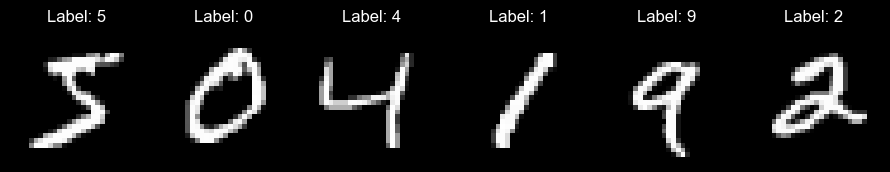

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_trian1[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Label: {y_train1[i]}')
    ax.axis('off')
plt.tight_layout(); plt.show()

In [7]:
X_train = X_trian1[:8000].astype(np.float32) /255
y_train = y_train1[:8000].astype('int64')
X_val = X_trian1[50000:51000].astype('float32') / 255.0
y_val = y_train1[50000:51000].astype('int64')
X_test = X_test[:2000].astype('float32') / 255.0
y_test = y_test[:2000].astype('int64')

print('Train:', X_train.shape, 'validation:', X_val.shape, 'test:', X_test.shape)
print('Input dtype / range:', X_train.dtype, X_train.min(), X_train.max())
print('Label dtype:', y_train.dtype)

Train: (8000, 28, 28) validation: (1000, 28, 28) test: (2000, 28, 28)
Input dtype / range: float32 0.0 1.0
Label dtype: int64


In [8]:
X_train = torch.tensor(X_trian1[:8000]).float()/255.0
X_val = torch.tensor(X_trian1[50000:51000]).float() /255.0
X_test = torch.tensor(X_test[:2000]).float()/255.0


In [9]:
from torch.utils.data import TensorDataset,DataLoader

train_pt = TensorDataset(X_train,torch.from_numpy(y_train) )
val_pt = TensorDataset(X_val,torch.from_numpy(y_val) )

train_loader = DataLoader(train_pt,batch_size=128,shuffle=True)
val_loader = DataLoader(val_pt,batch_size=128,shuffle=False)

In [10]:
# see one batch
batch_x_pt,batch_y_pt = next(iter(train_loader))
print('Torch batch:', batch_x_pt.shape, batch_y_pt.shape)

Torch batch: torch.Size([128, 28, 28]) torch.Size([128])


In [11]:
from tensorflow import keras
model_tf = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10)
])
model_tf.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model_tf.get_layer('flatten')

<Flatten name=flatten, built=True>

In [15]:
from torch import nn
model_pt = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784,64),
    nn.ReLU(),
    nn.Linear(64,10),
)
print(model_pt)
print(model_pt.parameters())

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=64, bias=True)
  (2): ReLU()
  (3): Linear(in_features=64, out_features=10, bias=True)
)
<generator object Module.parameters at 0x00000178F6FA8660>


In [16]:
# se param
tot_parm = 0
for p in model_pt.parameters():
    parm_count = p.numel()
    tot_parm += parm_count
    print('Each lauer',parm_count)

print(tot_parm)


Each lauer 50176
Each lauer 64
Each lauer 640
Each lauer 10
50890


In [17]:
print(model_pt(X_train[:2]))
model_pt(X_train[:2]).shape

# batch size here is 2 means 2 X inputed and 10 for each outputed
# these are logit outputs

tensor([[ 0.1069, -0.0917, -0.1718,  0.0632,  0.1981,  0.0196, -0.0832,  0.1390,
          0.1356,  0.0677],
        [ 0.0055, -0.0670, -0.1207,  0.0373,  0.1839,  0.0019,  0.0034,  0.0717,
          0.1019,  0.1065]], grad_fn=<AddmmBackward0>)


torch.Size([2, 10])

In [18]:
np.sum([-0.0211, -0.1230, -0.0720, -0.0300,  0.0856, -0.0604, -0.1391, -0.0044,
          0.1150, -0.0343])

-0.28369999999999995

In [19]:
## Loss and optimizer
loss_pt = nn.CrossEntropyLoss()
optimizer_pt = torch.optim.Adam(model_pt.parameters(), lr=0.001)

In [41]:
import torch
from torch import nn, optim  # ۱. تغییر امپورت

# ۲. ساخت نمونه از اپتیمایزر و تابع زیان (این دو خط قبل از حلقه لازم هستند)
optimizer = optim.Adam(model_pt.parameters(), lr=0.001)  # یا optim.SGD
loss_pt = nn.CrossEntropyLoss()

torch_train_loss = []
torch_val_loss = []
torch_val_acc = []
max_epoch = 3

for epoch in range(max_epoch):
    model_pt.train()
    total_loss = 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        logits = model_pt(images)
        loss = loss_pt(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)

    model_pt.eval()
    val_loss = 0
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            logits = model_pt(images)
            val_loss += loss_pt(logits, labels).item() * len(images)

            correct += (logits.argmax(dim=1) == labels).sum().item()

    torch_train_loss.append(total_loss / len(train_pt))
    torch_val_loss.append(val_loss / len(val_pt))
    torch_val_acc.append(correct / len(val_pt))

    print(f'Epoch {epoch+1}: train loss={torch_train_loss[-1]:.4f}, '
          f'validation accuracy={torch_val_acc[-1]:.3f}')

Epoch 1: train loss=0.2157, validation accuracy=0.917
Epoch 2: train loss=0.1944, validation accuracy=0.912
Epoch 3: train loss=0.1782, validation accuracy=0.915


In [42]:
for images , labels in train_loader:
    print(images.shape)
    print(len(labels))

torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size([128, 28, 28])
128
torch.Size

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import tensorflow as tf
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

# ۱. دریافت داده‌های اولیه
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = tf.keras.datasets.mnist.load_data()

# ۲. تقسیم‌بندی و تبدیل یک‌باره به تانسور (جلوگیری از تقسیم دوباره بر 255)
X_train = torch.tensor(X_train_raw[:8000], dtype=torch.float32) / 255.0
y_train = torch.tensor(y_train_raw[:8000], dtype=torch.long)

X_val = torch.tensor(X_train_raw[50000:51000], dtype=torch.float32) / 255.0
y_val = torch.tensor(y_train_raw[50000:51000], dtype=torch.long)

X_test = torch.tensor(X_test_raw[:2000], dtype=torch.float32) / 255.0
y_test = torch.tensor(y_test_raw[:2000], dtype=torch.long)

# ۳. ساخت DataLoader
train_pt = TensorDataset(X_train, y_train)
val_pt = TensorDataset(X_val, y_val)

train_loader = DataLoader(train_pt, batch_size=128, shuffle=True)
val_loader = DataLoader(val_pt, batch_size=128, shuffle=False)

# ۴. تعریف مدل
model_pt = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

# ۵. تعریف تابع زیان و اپتیمایزر
loss_pt = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_pt.parameters(), lr=0.001)

# ۶. حلقه آموزش و اعتبارسنجی
torch_train_loss, torch_val_loss, torch_val_acc = [], [], []
max_epoch = 3

for epoch in range(max_epoch):
    model_pt.train()
    total_loss = 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        logits = model_pt(images)
        loss = loss_pt(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)

    model_pt.eval()
    val_loss = 0
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            logits = model_pt(images)
            val_loss += loss_pt(logits, labels).item() * len(images)
            correct += (logits.argmax(dim=1) == labels).sum().item()

    torch_train_loss.append(total_loss / len(train_pt))
    torch_val_loss.append(val_loss / len(val_pt))
    torch_val_acc.append(correct / len(val_pt))

    print(f'Epoch {epoch+1}: train loss={torch_train_loss[-1]:.4f}, '
          f'validation accuracy={torch_val_acc[-1]:.3f}')

# ۷. ارزیابی نهایی رو داده‌های تست (Test - Slim Version)
model_pt.eval()
with torch.no_grad():
    test_logits = model_pt(X_test)
    test_loss = loss_pt(test_logits, y_test).item()
    test_acc = (test_logits.argmax(dim=1) == y_test).float().mean().item()

print(f'\nTorch Test Result -> Loss: {test_loss:.4f} | Accuracy: {test_acc:.3f}')

Epoch 1: train loss=1.2914, validation accuracy=0.835
Epoch 2: train loss=0.4766, validation accuracy=0.876
Epoch 3: train loss=0.3528, validation accuracy=0.885

Torch Test Result -> Loss: 0.4481 | Accuracy: 0.869
